In [1]:
if (!requireNamespace("mixOmics", quietly = TRUE)) {
    options(BioC_mirror = "https://bioconductor.org")
    BiocManager::install(version = "3.18", force = TRUE)
    BiocManager::install("mixOmics")
}

library(mixOmics)
library(BiocParallel)
library(svglite)

Loading required package: MASS

Loading required package: lattice

Loading required package: ggplot2


Loaded mixOmics 6.26.0
Thank you for using mixOmics!
Tutorials: http://mixomics.org
Bookdown vignette: https://mixomicsteam.github.io/Bookdown
Questions, issues: Follow the prompts at http://mixomics.org/contact-us
Cite us:  citation('mixOmics')




In [2]:
DATA_DIR <- "/home/mariya/Data/pallas"
MIXOMICS_DIR <- file.path(DATA_DIR, "mixOmics/models_20260813")
PREDICTIONS_OUTPUT_DIR <- "/home/mariya/Development/pallas/reports/output/predictions/bimodal"
REPORT_OUTPUT_DIR <- "/home/mariya/Development/pallas/reports/output/evaluation/bimodal"

DATA_DIR <- file.path(DATA_DIR, "mlomix_datasets")

TEST_DATA_DIR <- file.path(DATA_DIR, "labeled-diagnostic-bimodal-reduced")
METH_TEST_FILE <- file.path(TEST_DATA_DIR, "features.dnam.csv")
GEX_TEST_FILE <- file.path(TEST_DATA_DIR, "features.gex.csv")
LABELS_TEST_FILE <- file.path(TEST_DATA_DIR, "labels.csv")

GEX_MODEL_FILE <- file.path(MIXOMICS_DIR, "gex_model.rds")
DNAM_MODEL_FILE <- file.path(MIXOMICS_DIR, "dnam_model.rds")
DIABLO_MODEL_FILE <- file.path(MIXOMICS_DIR, "diablo_model.rds")

# Make output directory if it doesn't exist
if (!dir.exists(PREDICTIONS_OUTPUT_DIR)) {
    dir.create(PREDICTIONS_OUTPUT_DIR, recursive = TRUE)
}

In [3]:
BLUE="#667ec8"
RED="#d64a51"
YELLOW="#d6ce2f"
GREEN="#90c23a"
LIGHTBLUE="#60acda"
PURPLE="#9454b0"

DIST <- "centroids.dist"

In [4]:
gex_model    <- readRDS(GEX_MODEL_FILE)
dnam_model   <- readRDS(DNAM_MODEL_FILE)
diablo_model <- readRDS(DIABLO_MODEL_FILE)


In [5]:
source("helpers.R")
test_data <- data(GEX_TEST_FILE, METH_TEST_FILE, LABELS_TEST_FILE)

Samples: 1227 
GEX features: 1121 
DNAm features: 1186 
Subtypes: AML, APL-PML::RARA AML, CBFA2T3::GLIS2 AML, CBFB::MYH11 AML, CEBPAalt AML, DEK::NUP214 AML, ETV6-r AML, KAT6A-r AML, KMT2A-r AML, NPM1alt AML, NUP98-r AML, RUNX1::RUNX1T1 B-ALL, BCR::ABL1 B-ALL, BCR::ABL1-like B-ALL, DUX4-r B-ALL, ETV6::RUNX1 B-ALL, ETV6::RUNX1-like B-ALL, high hyperdiploid B-ALL, iAMP21 B-ALL, KMT2A-r B-ALL, MEF2D-r B-ALL, PAX5alt B-ALL, TCF3::PBX1 B-ALL, ZNF384-r Non-leukemic T-ALL 


In [6]:
X_gex_test <- test_data$X_gex
X_dnam_test <- test_data$X_dnam
Y_test     <- test_data$Y
Y_train   <- test_data$Y

head(X_gex_test)
head(X_dnam_test)
head(Y_test)

,ENSG00000184507,ENSG00000079102,ENSG00000248329,ENSG00000101115,ENSG00000172752,ENSG00000097007,ENSG00000132185,ENSG00000167880,ENSG00000177469,ENSG00000188064,⋯,ENSG00000170396,ENSG00000130702,ENSG00000187325,ENSG00000169213,ENSG00000186980,ENSG00000182747,ENSG00000144681,ENSG00000072954,ENSG00000181007,ENSG00000107819
ALL_1000,-1.608643,-1.608643,15.995107,4.8418488,-1.4407131,6.202016,-0.8269021,0.3324897,1.0468822,-1.306680,⋯,-0.2482395,1.155457,6.090830,-1.60864328,-1.608643,-1.6086433,-1.269090,0.7956456,2.456942,6.361923
ALL_1003,7.866846,-1.608643,-1.608643,-0.1704226,-1.6086433,6.221609,-1.6086433,-0.5538530,-0.7979199,-1.373961,⋯,-1.6086433,-1.147371,4.677110,0.26710648,-1.608643,-1.1408426,-1.608643,-1.2343983,3.309382,5.515478
ALL_1005,-1.608643,-1.608643,-1.608643,3.0300396,-1.5171299,5.962302,5.6071701,0.6443205,-0.6988636,-1.608643,⋯,-1.6086433,1.857859,6.355210,-0.24149963,-1.608643,-1.6086433,3.743243,3.2675844,3.515856,4.569093
ALL_1019,-1.608643,-1.608643,-1.608643,7.0165835,-1.6086433,5.654076,1.5010946,3.2958788,-0.2369391,-1.608643,⋯,-1.6086433,1.988980,5.567993,0.44466570,-1.608643,-1.6086433,-1.161472,3.8516648,2.002225,5.698553
ALL_1023,6.295659,-1.608643,-1.608643,4.0362302,-0.4718155,6.586559,-1.0246909,5.4514953,2.5433950,-1.608643,⋯,0.2861806,-0.133622,4.903089,1.57325962,-1.608643,-0.8427656,-1.364855,0.2819973,2.888247,4.372993
ALL_1026,-1.384271,-1.608643,7.200832,-0.3788483,-1.6086433,6.458333,0.3933072,7.1349388,-0.9366025,7.595660,⋯,-1.6086433,2.223308,5.783929,0.09725186,-1.608643,-1.6086433,-1.608643,1.1623027,2.910556,5.311609


,cg10443049,cg07275648,cg00760938,cg04646674,cg12183594,cg03732020,cg14992144,cg13799263,cg08166720,cg00015639,⋯,cg01955153,cg26092233,cg18631798,cg21927946,cg11551919,cg01883662,cg20294319,cg12737392,cg09291834,cg11414821
ALL_1000,0.8325,0.9452,0.0400,0.9366,0.9854,0.7879,0.0186,0.9181,0.9419,0.2988,⋯,0.1614,0.0677,0.0333,0.2134,0.9773,0.9641,0.0702,0.0862,0.8104,0.0315
ALL_1003,0.9219,0.6754,0.1550,0.9236,0.9849,0.9087,0.0272,0.7213,0.9059,0.7597,⋯,0.0889,0.1056,0.0643,0.7567,0.9731,0.9196,0.0946,0.0913,0.0193,0.0256
ALL_1005,0.9113,0.9435,0.0375,0.6264,0.9850,0.9844,0.0230,0.7807,0.9334,0.9095,⋯,0.2638,0.0489,0.0296,0.0678,0.9645,0.9251,0.0899,0.1216,0.4870,0.0326
ALL_1019,0.7243,0.9433,0.0757,0.9088,0.9829,0.9830,0.0267,0.8941,0.4691,0.6096,⋯,0.1940,0.0529,0.0354,0.0220,0.3327,0.1337,0.0656,0.0774,0.1054,0.0233
ALL_1023,0.8656,0.9308,0.1669,0.8532,0.9857,0.8091,0.0480,0.9283,0.9532,0.8493,⋯,0.2563,0.1559,0.0972,0.0441,0.9504,0.9194,0.0604,0.1027,0.1858,0.0363
ALL_1026,0.9320,0.6853,0.0826,0.8681,0.9848,0.9876,0.0354,0.9055,0.9592,0.7046,⋯,0.1624,0.1184,0.0643,0.0251,0.3294,0.1498,0.0533,0.0888,0.0324,0.0294


[1] B-ALL, DUX4-r      B-ALL, PAX5alt     B-ALL, MEF2D-r     B-ALL, ZNF384-r   
[5] B-ALL, ETV6::RUNX1 B-ALL, PAX5alt    
25 Levels: AML, APL-PML::RARA AML, CBFA2T3::GLIS2 ... T-ALL

In [7]:
# X_gex_test  <- X_gex_test[,  colnames(gex_model$X)]
# X_dnam_test <- X_dnam_test[, colnames(dnam_model$X)]

# Verify
cat("GEX names match: ",  all(colnames(X_gex_test)  == colnames(gex_model$X)),  "\n")
cat("DNAm names match:",  all(colnames(X_dnam_test) == colnames(dnam_model$X)), "\n")

# Show number of features in test set vs model
cat("GEX features in test set: ", ncol(X_gex_test), " vs model: ", ncol(gex_model$X), "\n")
cat("DNAm features in test set: ", ncol(X_dnam_test), " vs model: ", ncol(dnam_model$X), "\n")

GEX names match:  TRUE 
DNAm names match: TRUE 


GEX features in test set:  1121  vs model:  1121 
DNAm features in test set:  1186  vs model:  1186 


In [8]:

gex_pred    <- predict(gex_model,    X_gex_test,  dist = DIST)
dnam_pred   <- predict(dnam_model,   X_dnam_test, dist = DIST)
diablo_pred <- predict(diablo_model, newdata = list(gex = X_gex_test,
                                                     dnam = X_dnam_test),
                                                     dist = DIST)

In [9]:
# Extract predicted classes at final component
ncomp_gex_final    <- gex_model$ncomp
ncomp_dnam_final   <- dnam_model$ncomp
ncomp_diablo_final <- diablo_model$ncomp

gex_class    <- gex_pred$class$centroids.dist[,    ncomp_gex_final]
dnam_class   <- dnam_pred$class$centroids.dist[,   ncomp_dnam_final]
diablo_class <- diablo_pred$WeightedVote$centroids.dist[, ncol(diablo_pred$WeightedVote$centroids.dist)]

In [10]:
# Make predictiosn dir if not exist
if (!dir.exists(PREDICTIONS_OUTPUT_DIR)) {
    dir.create(PREDICTIONS_OUTPUT_DIR, recursive = TRUE)
}

# After true_label, create three cols: gex_pred, dnam_pred, diablo_pred
# that contain the prediction from the MAX_COMP component for each model
# Keep the rest of the columns as well
predictions_df <- data.frame(
    "Sample" = rownames(X_gex_test),
    "True subtype" = Y_test,
    "GEX sPLS-DA prediction" = gex_class,
    "DNAm sPLS-DA prediction" = dnam_class,
    "DIABLO sPLS-DA prediction" = diablo_class,
    "GEX" = gex_pred$class,
    "DNAm" = dnam_pred$class,
    "DIABLO" = diablo_pred$class,
    check.names = FALSE
)

# Sort by "True subtype", then "Sample"
predictions_df <- predictions_df[order(predictions_df$`True subtype`, predictions_df$Sample), ]

write.csv(predictions_df, file.path(PREDICTIONS_OUTPUT_DIR, "bimodal_predictions_labeled.csv"), row.names = FALSE)

In [11]:
# Build results data frame
results_df <- data.frame(
  sample_id   = rownames(X_gex_test),
  true_label  = as.character(Y_test),
  gex_pred    = as.character(gex_class),
  dnam_pred   = as.character(dnam_class),
  diablo_pred = as.character(diablo_class),
  row.names   = NULL
)

head(results_df)

,sample_id,true_label,gex_pred,dnam_pred,diablo_pred
,<chr>,<chr>,<chr>,<chr>,<chr>
1,ALL_1000,"B-ALL, DUX4-r","B-ALL, DUX4-r","B-ALL, DUX4-r","B-ALL, DUX4-r"
2,ALL_1003,"B-ALL, PAX5alt","B-ALL, PAX5alt","B-ALL, PAX5alt","B-ALL, PAX5alt"
3,ALL_1005,"B-ALL, MEF2D-r","B-ALL, MEF2D-r","B-ALL, MEF2D-r","B-ALL, MEF2D-r"
4,ALL_1019,"B-ALL, ZNF384-r","B-ALL, ZNF384-r","B-ALL, ZNF384-r","B-ALL, ZNF384-r"
5,ALL_1023,"B-ALL, ETV6::RUNX1","B-ALL, ETV6::RUNX1","B-ALL, ETV6::RUNX1","B-ALL, ETV6::RUNX1"
6,ALL_1026,"B-ALL, PAX5alt","B-ALL, PAX5alt","B-ALL, PAX5alt","B-ALL, PAX5alt"


In [12]:

library(ggplot2)
library(dplyr)
library(tidyr)
library(ggrepel)

# Per-class F1
per_class_f1 <- function(true, pred, classes) {
  do.call(rbind, lapply(classes, function(c) {
    tp <- sum(pred == c & true == c)
    fp <- sum(pred == c & true != c)
    fn <- sum(pred != c & true == c)
    precision <- ifelse((tp + fp) == 0, 0, tp / (tp + fp))
    recall    <- ifelse((tp + fn) == 0, 0, tp / (tp + fn))
    f1        <- ifelse((precision + recall) == 0, 0,
                        2 * precision * recall / (precision + recall))
    data.frame(Class = c, Precision = round(precision, 3),
               Recall = round(recall, 3), F1 = round(f1, 3))
  }))
}

classes <- levels(Y_test)

f1_gex    <- per_class_f1(Y_test, gex_class,    classes); f1_gex$Model    <- "GEX"
f1_dnam   <- per_class_f1(Y_test, dnam_class,   classes); f1_dnam$Model   <- "DNAm"
f1_diablo <- per_class_f1(Y_test, diablo_class, classes); f1_diablo$Model <- "DIABLO"

f1_all  <- rbind(f1_gex, f1_dnam, f1_diablo)
f1_wide <- f1_all |> select(Class, Model, F1) |>
  pivot_wider(names_from = Model, values_from = F1)

# Add class sizes
class_n_train       <- as.data.frame(table(Y_train))
colnames(class_n_train) <- c("Class", "n_train")
f1_wide        <- left_join(f1_wide, class_n_train, by = "Class")

class_n_test        <- as.data.frame(table(Y_test))
colnames(class_n_test) <- c("Class", "n_test")
f1_wide        <- left_join(f1_wide, class_n_test, by = "Class")
f1_wide


Attaching package: ‘dplyr’


The following object is masked from ‘package:MASS’:

    select


The following objects are masked from ‘package:stats’:

    filter, lag


The following objects are masked from ‘package:base’:

    intersect, setdiff, setequal, union




Class,GEX,DNAm,DIABLO,n_train,n_test
<chr>,<dbl>,<dbl>,<dbl>,<int>,<int>
"AML, APL-PML::RARA",0.963,0.963,0.963,14,14
"AML, CBFA2T3::GLIS2",0.870,0.783,0.833,13,13
"AML, CBFB::MYH11",0.994,0.975,0.994,83,83
"AML, CEBPAalt",0.972,0.978,0.978,71,71
"AML, DEK::NUP214",1.000,0.943,0.812,27,27
"AML, ETV6-r",0.800,0.640,0.889,9,9
"AML, KAT6A-r",1.000,0.200,0.700,7,7
"AML, KMT2A-r",0.923,0.802,0.896,295,295
"AML, NPM1alt",0.884,0.908,0.868,165,165


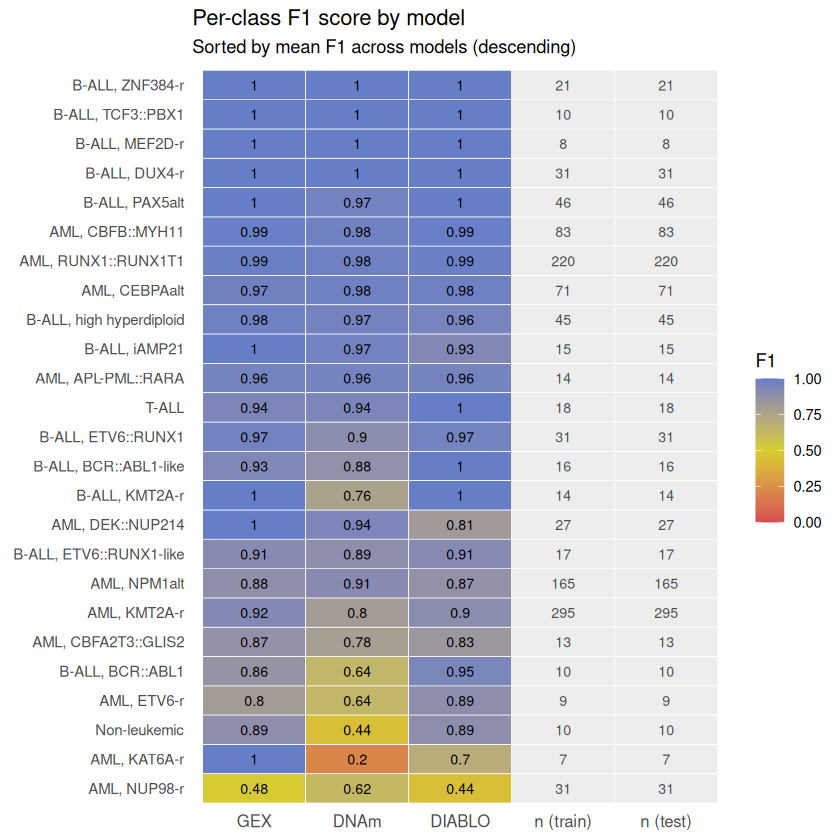

In [13]:
# Add average F1 column for sorting
f1_wide <- f1_wide %>%
  mutate(avg_F1 = (GEX + DNAm + DIABLO) / 3)

# Pivot to long including n_train and n_test as separate tile columns
f1_long <- f1_wide %>%
  pivot_longer(cols = c("GEX", "DNAm", "DIABLO"),
               names_to = "Model", values_to = "F1")

# Create n_train and n_test rows as separate "columns"
n_df <- f1_wide %>%
  select(Class, n_train, n_test, avg_F1) %>%
  pivot_longer(cols = c("n_train", "n_test"),
               names_to = "Model", values_to = "n_val") %>%
  mutate(F1 = NA)

# Combine
f1_plot_df <- bind_rows(
  f1_long %>% mutate(n_val = NA),
  n_df
) %>%
  mutate(Model = factor(Model,
                        levels = c("GEX", "DNAm", "DIABLO",
                                   "n_train", "n_test")))

ggplot(f1_plot_df,
       aes(x = Model,
           y = reorder(Class, avg_F1),
           fill = F1)) +
  geom_tile(colour = "white") +
  # F1 values
  geom_text(data = filter(f1_plot_df, Model %in% c("GEX","DNAm","DIABLO")),
            aes(label = round(F1, 2)), size = 3) +
  # n_train and n_test values
  geom_text(data = filter(f1_plot_df, Model %in% c("n_train","n_test")),
            aes(label = n_val), size = 3, colour = "grey30") +
  scale_fill_gradient2(low       = RED,
                       mid       = YELLOW,
                       high      = BLUE,
                       midpoint  = 0.5,
                       limits    = c(0, 1),
                       na.value  = "grey93",
                       name      = "F1") +
  scale_x_discrete(labels = c("GEX", "DNAm", "DIABLO",
                               "n (train)", "n (test)")) +
  labs(title = "Per-class F1 score by model",
       subtitle = "Sorted by mean F1 across models (descending)",
       x = NULL, y = NULL) +
  theme_minimal() +
  theme(axis.text.x  = element_text(size = 10),
        axis.text.y  = element_text(size = 9),
        legend.position = "right",
        panel.grid   = element_blank())

  # Save as svg
ggsave(file.path(REPORT_OUTPUT_DIR, "per_class_f1_plot.svg"),
       width = 8, height = 6, units = "in")

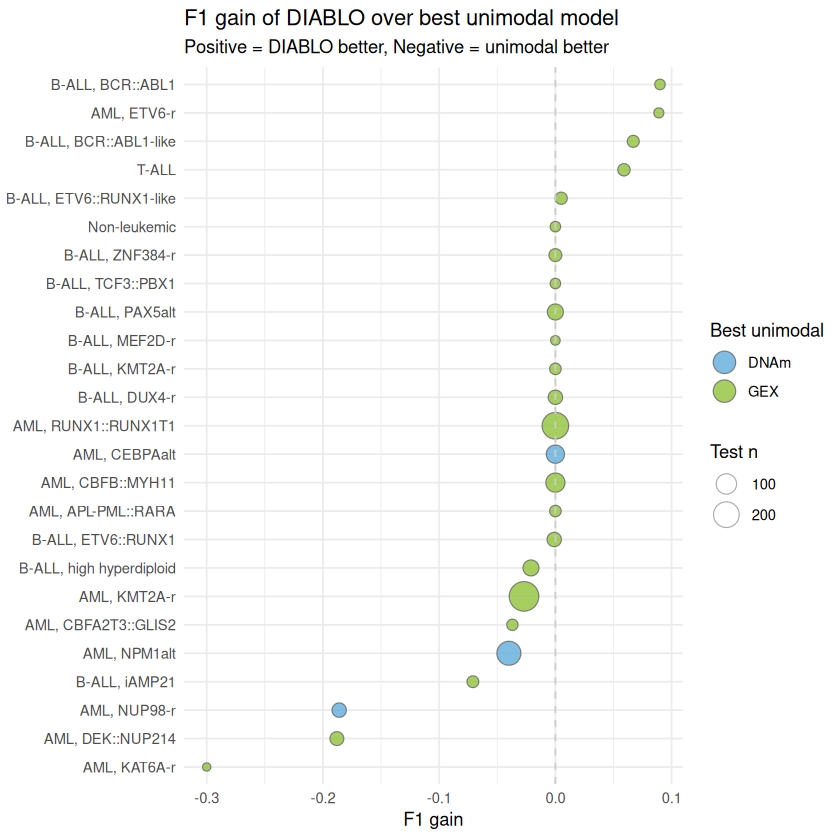

In [14]:
f1_wide <- f1_wide |>
  mutate(
    Best_unimodal    = pmax(GEX, DNAm),
    DIABLO_gain      = DIABLO - Best_unimodal,
    Best_unimodal_name = ifelse(GEX >= DNAm, "GEX", "DNAm")
  )

ggplot(f1_wide, aes(x = DIABLO_gain,
                    y = reorder(Class, DIABLO_gain),
                    fill = Best_unimodal_name,
                    size = n_test)) +
  geom_point(shape = 21, alpha = 0.8, colour = "grey40", stroke = 0.5) +
  geom_vline(xintercept = 0, linetype = "dashed", colour = "grey80") +
  scale_fill_manual(values = c(GEX = GREEN, DNAm = LIGHTBLUE), name = "Best unimodal") +
  scale_size_continuous(range = c(2, 8), name = "Test n") +
  guides(
    fill = guide_legend(override.aes = list(size = 6, stroke = 0.5, colour = "grey40")),
    size = guide_legend(override.aes = list(colour = "grey60", stroke = 0.5))
  ) +
  labs(title    = "F1 gain of DIABLO over best unimodal model",
       subtitle = "Positive = DIABLO better, Negative = unimodal better",
       x = "F1 gain", y = NULL) +
  theme_minimal()
  # Save as svg
ggsave(file.path(REPORT_OUTPUT_DIR, "diablo_gain_plot.svg"),
       width = 8, height = 6, units = "in")

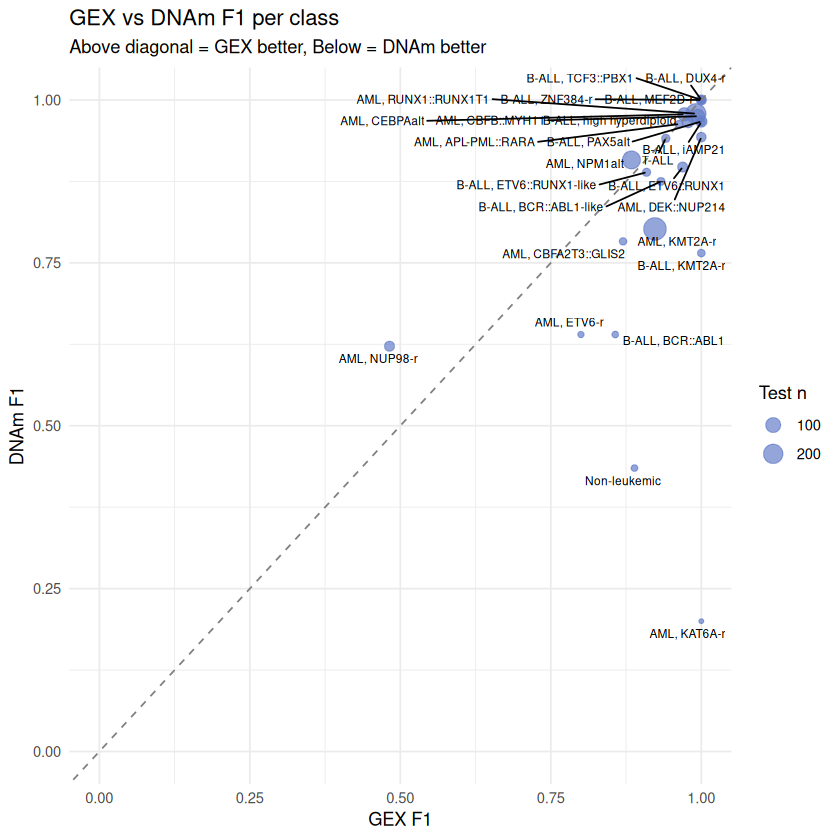

In [15]:
ggplot(f1_wide, aes(x = GEX, y = DNAm, size = n_test, label = Class)) +
  geom_point(alpha = 0.7, colour = BLUE) +
  geom_abline(slope = 1, intercept = 0, linetype = "dashed", colour = "grey50") +
  geom_text_repel(size = 2.5, max.overlaps = 20) +
  xlim(0, 1) + ylim(0, 1) +
  labs(title = "GEX vs DNAm F1 per class",
       subtitle = "Above diagonal = GEX better, Below = DNAm better",
       x = "GEX F1", y = "DNAm F1", size = "Test n") +
  theme_minimal()

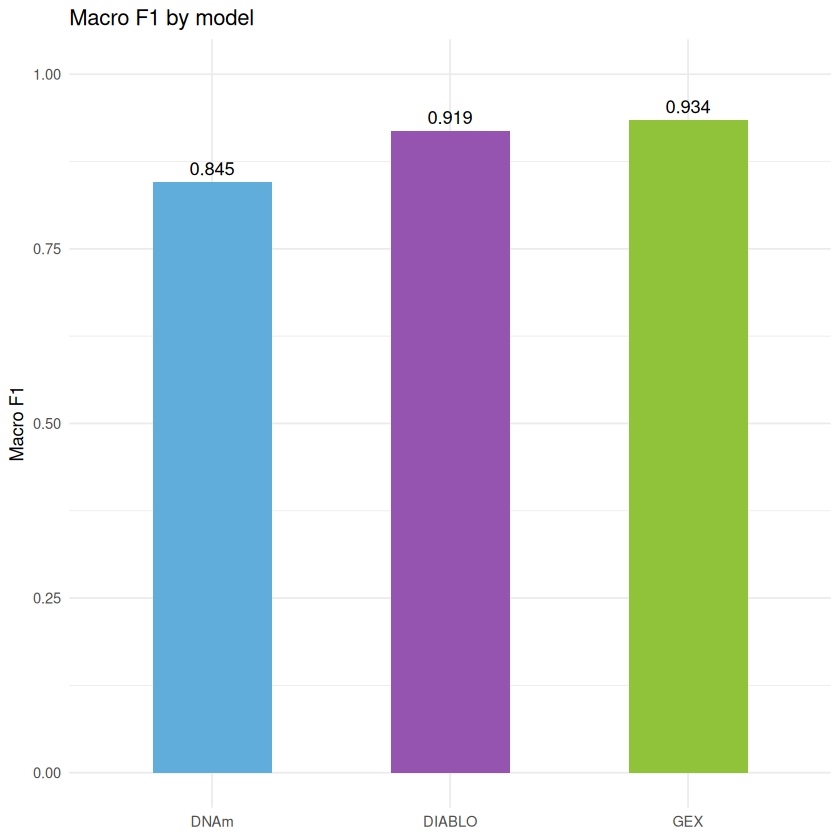

In [16]:
macro_f1 <- f1_all |>
  group_by(Model) |>
  summarise(MacroF1 = mean(F1), .groups = "drop")

ggplot(macro_f1, aes(x = reorder(Model, MacroF1), y = MacroF1, fill = Model)) +
  geom_bar(stat = "identity", width = 0.5) +
  geom_text(aes(label = round(MacroF1, 3)), vjust = -0.5) +
  scale_fill_manual(values = c(GEX = GREEN,
                                DNAm = LIGHTBLUE,
                                DIABLO = PURPLE)) +
  ylim(0, 1) +
  labs(title = "Macro F1 by model", x = NULL, y = "Macro F1") +
  theme_minimal() +
  theme(legend.position = "none")

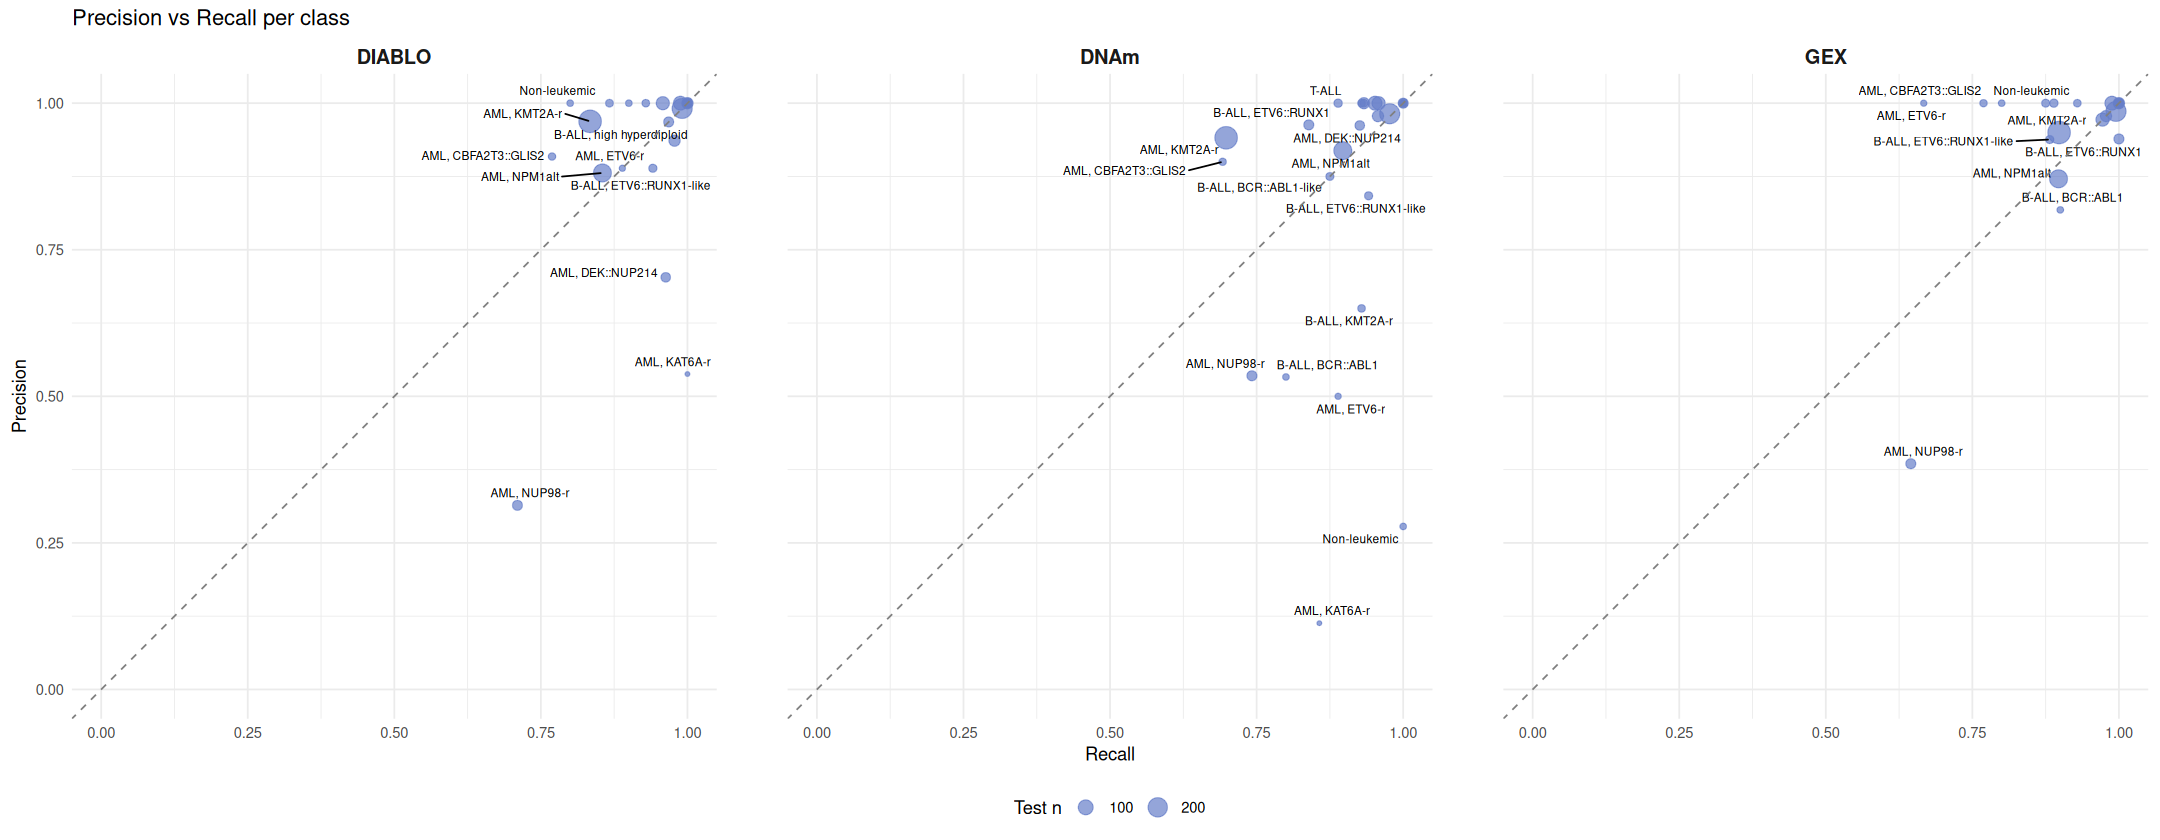

In [17]:
options(repr.plot.width = 18, repr.plot.height = 7)

class_n <- class_n_test %>% dplyr::rename(n = n_test)

plot_df <- left_join(f1_all, class_n, by = "Class")

ggplot(plot_df, aes(x = Recall, y = Precision, size = n, label = Class)) +
  geom_point(alpha = 0.7, colour = BLUE) +
  geom_text_repel(size = 2.5, max.overlaps = 15) +
  geom_abline(slope = 1, intercept = 0, linetype = "dashed", colour = "grey50") +
  facet_wrap(~ Model, nrow = 1) +
  xlim(0, 1) + ylim(0, 1) +
  coord_fixed(ratio = 1) +
  labs(title = "Precision vs Recall per class", size = "Test n") +
  theme_minimal() +
  theme(
    panel.spacing   = unit(1.5, "cm"),
    strip.text      = element_text(size = 12, face = "bold"),
    legend.position = "bottom"
  )

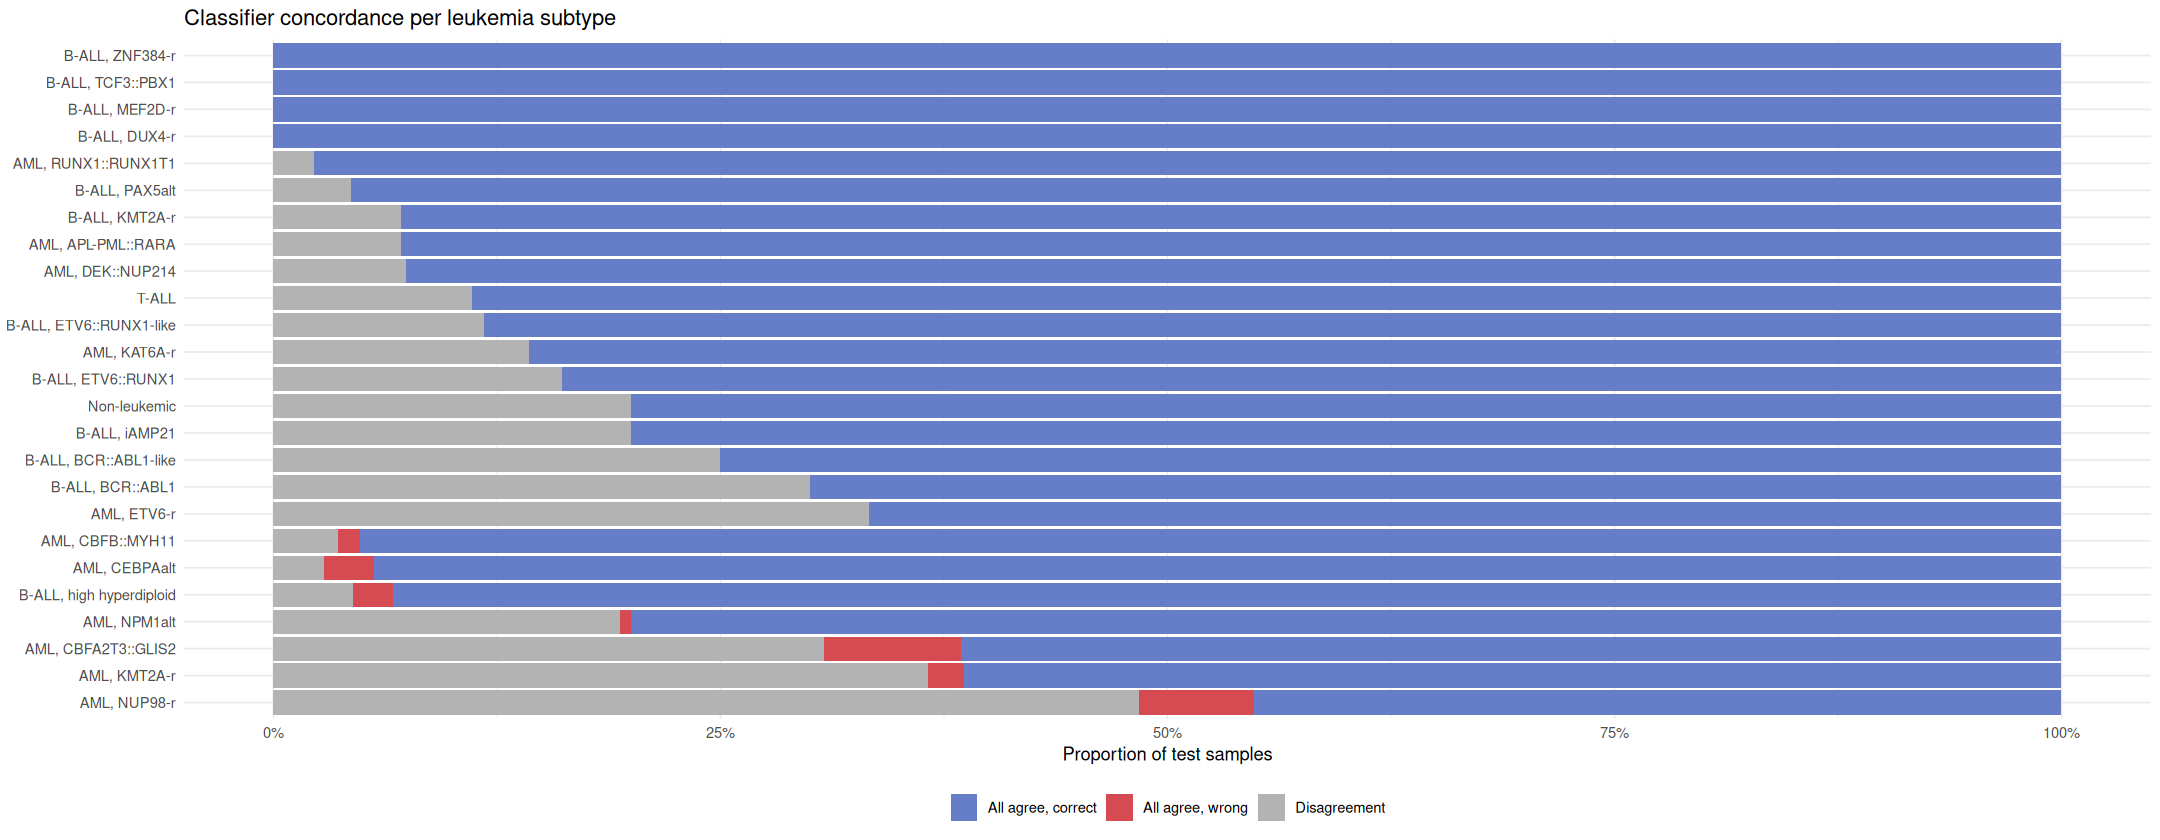

In [18]:
library(ggplot2)
library(dplyr)

# ============================================================
# Compute per-sample concordance
# ============================================================
results_df <- results_df |>
  mutate(
    # How many models agree with each other
    n_agree = (gex_pred == dnam_pred) +
              (gex_pred == diablo_pred) +
              (dnam_pred == diablo_pred),

    # All three agree
    all_agree = gex_pred == dnam_pred & dnam_pred == diablo_pred,

    # All three agree AND correct
    all_correct = all_agree & gex_pred == true_label,

    # Concordance label
    concordance = case_when(
      all_agree & gex_pred == true_label  ~ "All agree, correct",
      all_agree & gex_pred != true_label  ~ "All agree, wrong",
      !all_agree                           ~ "Disagreement"
    )
  )

# ============================================================
# 1. Stacked bar — concordance per true class
# ============================================================
conc_summary <- results_df |>
  group_by(true_label, concordance) |>
  summarise(n = n(), .groups = "drop") |>
  group_by(true_label) |>
  mutate(pct = n / sum(n))

ggplot(conc_summary,
       aes(x = pct,
           y = reorder(true_label, pct * (concordance == "All agree, correct")),
           fill = concordance)) +
  geom_bar(stat = "identity") +
  scale_fill_manual(values = c("All agree, correct" = BLUE,
                                "All agree, wrong"   = RED,
                                "Disagreement"       = "grey70")) +
  scale_x_continuous(labels = scales::percent) +
  labs(title = "Classifier concordance per leukemia subtype",
       x = "Proportion of test samples", y = NULL, fill = NULL) +
  theme_minimal() +
  theme(legend.position = "bottom")

# Save as svg
ggsave(file.path(REPORT_OUTPUT_DIR, "concordance_plot.svg"),
       width = 6, height = 6, units = "in")


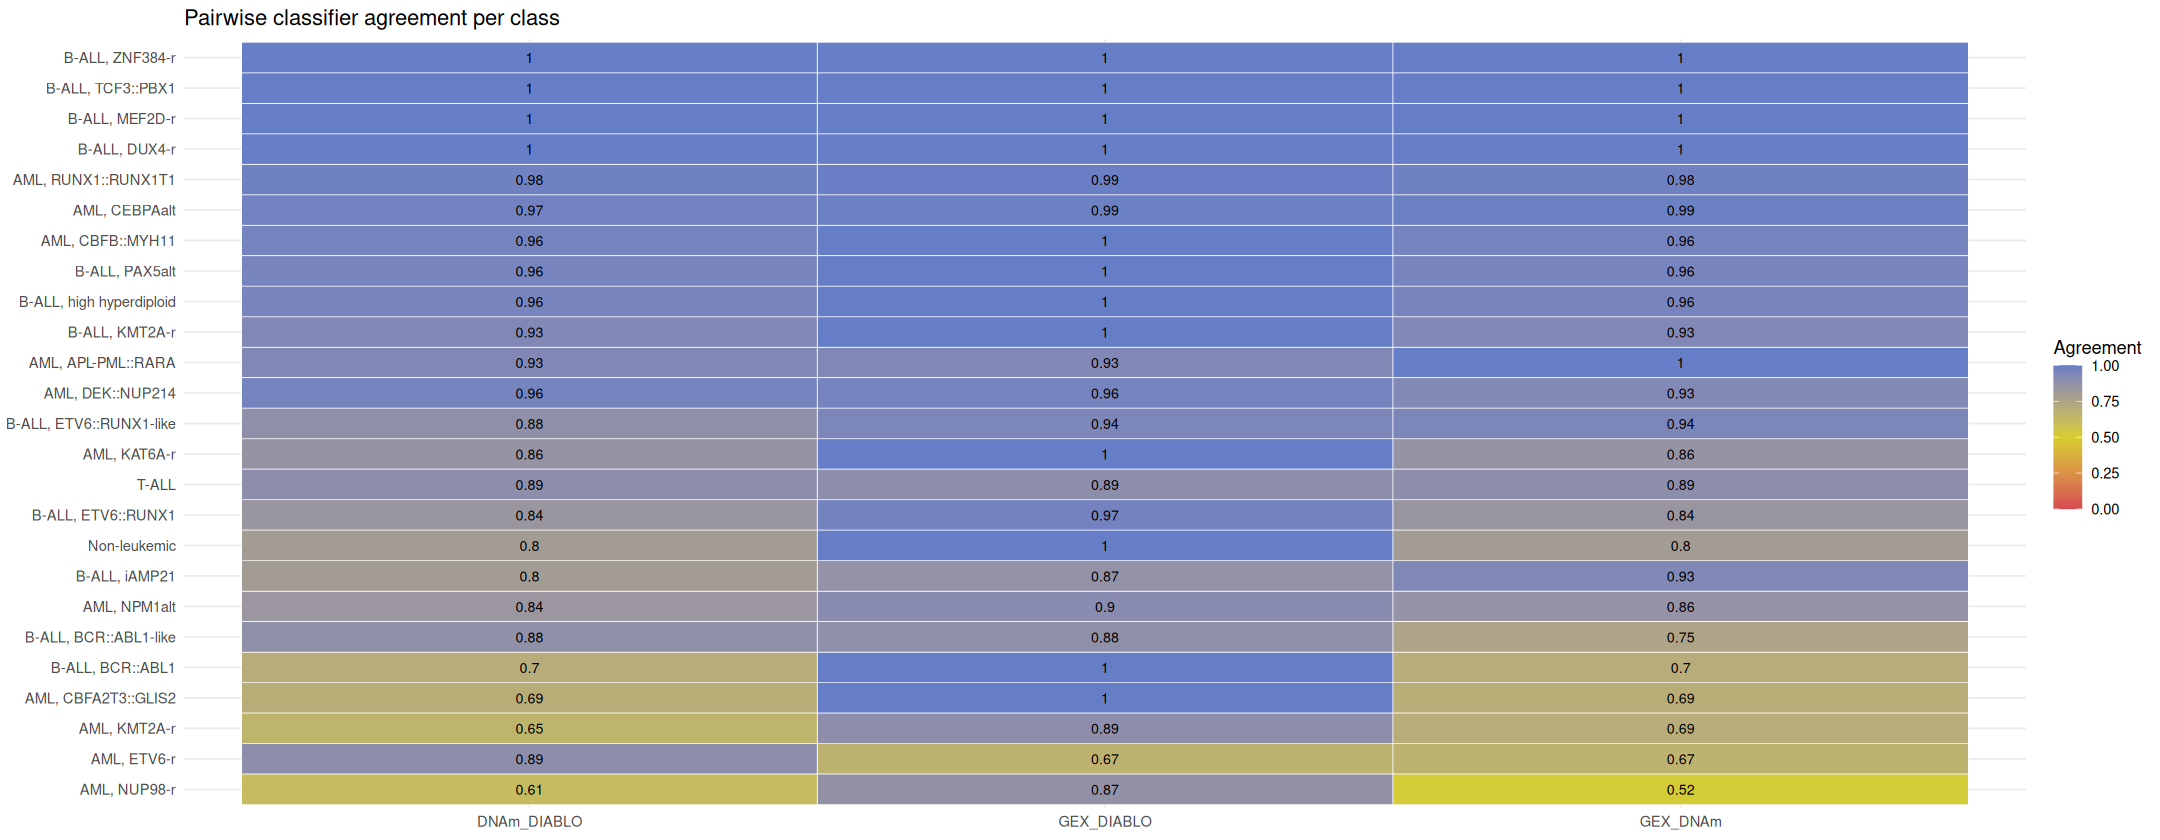

In [19]:

# ============================================================
# 2. Tile plot — pairwise agreement per class
# ============================================================
pairwise <- results_df |>
  group_by(true_label) |>
  summarise(
    GEX_DNAm    = mean(gex_pred == dnam_pred),
    GEX_DIABLO  = mean(gex_pred == diablo_pred),
    DNAm_DIABLO = mean(dnam_pred == diablo_pred),
    .groups = "drop"
  ) |>
  pivot_longer(cols = c("GEX_DNAm","GEX_DIABLO","DNAm_DIABLO"),
               names_to = "Pair", values_to = "Agreement")

ggplot(pairwise, aes(x = Pair,
                      y = reorder(true_label, Agreement),
                      fill = Agreement)) +
  geom_tile(colour = "white") +
  scale_fill_gradient2(low = RED, mid = YELLOW, high = BLUE,
                       midpoint = 0.5, limits = c(0, 1)) +
  geom_text(aes(label = round(Agreement, 2)), size = 3) +
  labs(title = "Pairwise classifier agreement per class",
       x = NULL, y = NULL, fill = "Agreement") +
  theme_minimal()

# Save as svg
ggsave(file.path(REPORT_OUTPUT_DIR, "pairwise_agreement_plot.svg"),
       width = 6, height = 6, units = "in")


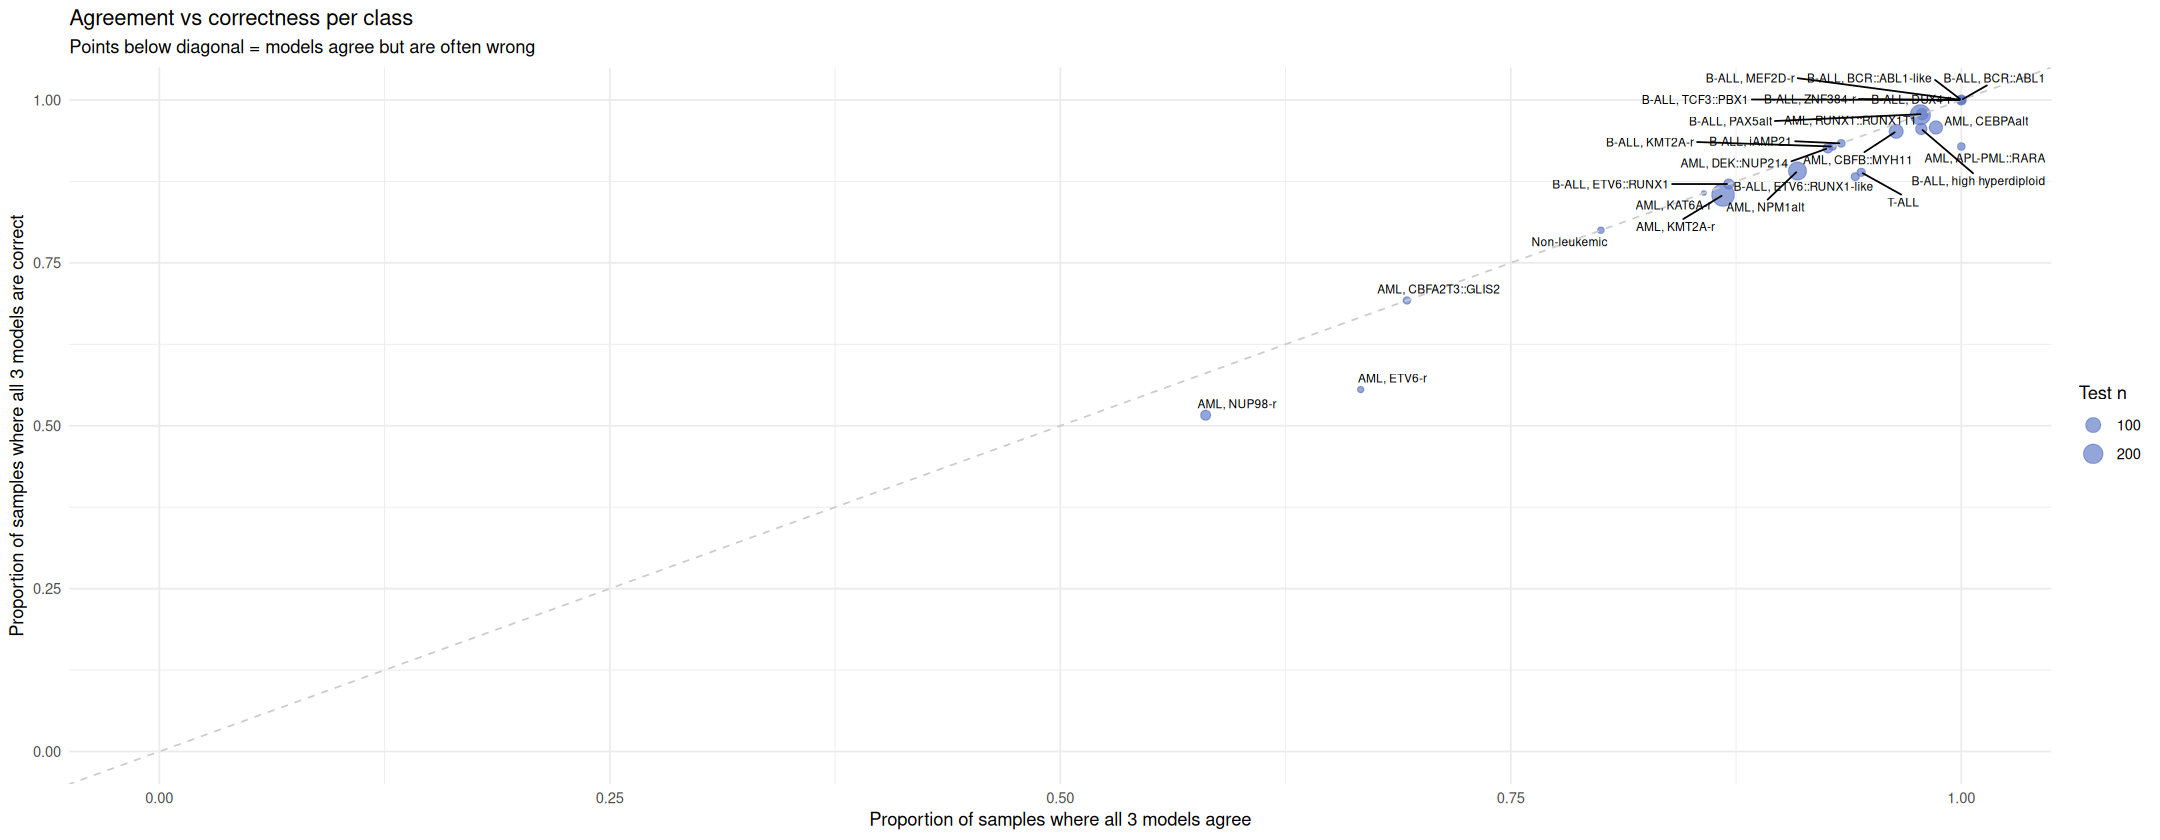

In [ ]:

# ============================================================
# 3. Scatter — per class: % all-agree vs % correct
# ============================================================
class_conc <- results_df |>
  group_by(true_label) |>
  summarise(
    n          = n(),
    pct_agree  = mean(all_agree),
    pct_correct = mean(gex_pred == true_label &
                       dnam_pred == true_label &
                       diablo_pred == true_label),
    .groups = "drop"
  )

ggplot(class_conc, aes(x = pct_agree, y = pct_correct,
                        size = n, label = true_label)) +
  geom_point(alpha = 0.7, colour = BLUE) +
  geom_abline(slope = 1, intercept = 0,
              linetype = "dashed", colour = "grey80") +
  geom_text_repel(size = 2.5, max.overlaps = 20) +
  xlim(0, 1) + ylim(0, 1) +
  labs(title    = "Agreement vs correctness per class",
       subtitle = "Points below diagonal = models agree but are often wrong",
       x = "Proportion of samples where all 3 models agree",
       y = "Proportion of samples where all 3 models are correct",
       size = "Test n") +
  theme_minimal()

# Save as svg
ggsave(file.path(REPORT_OUTPUT_DIR, "agreement_correctness_plot.svg"),
       width = 8, height = 6, units = "in")

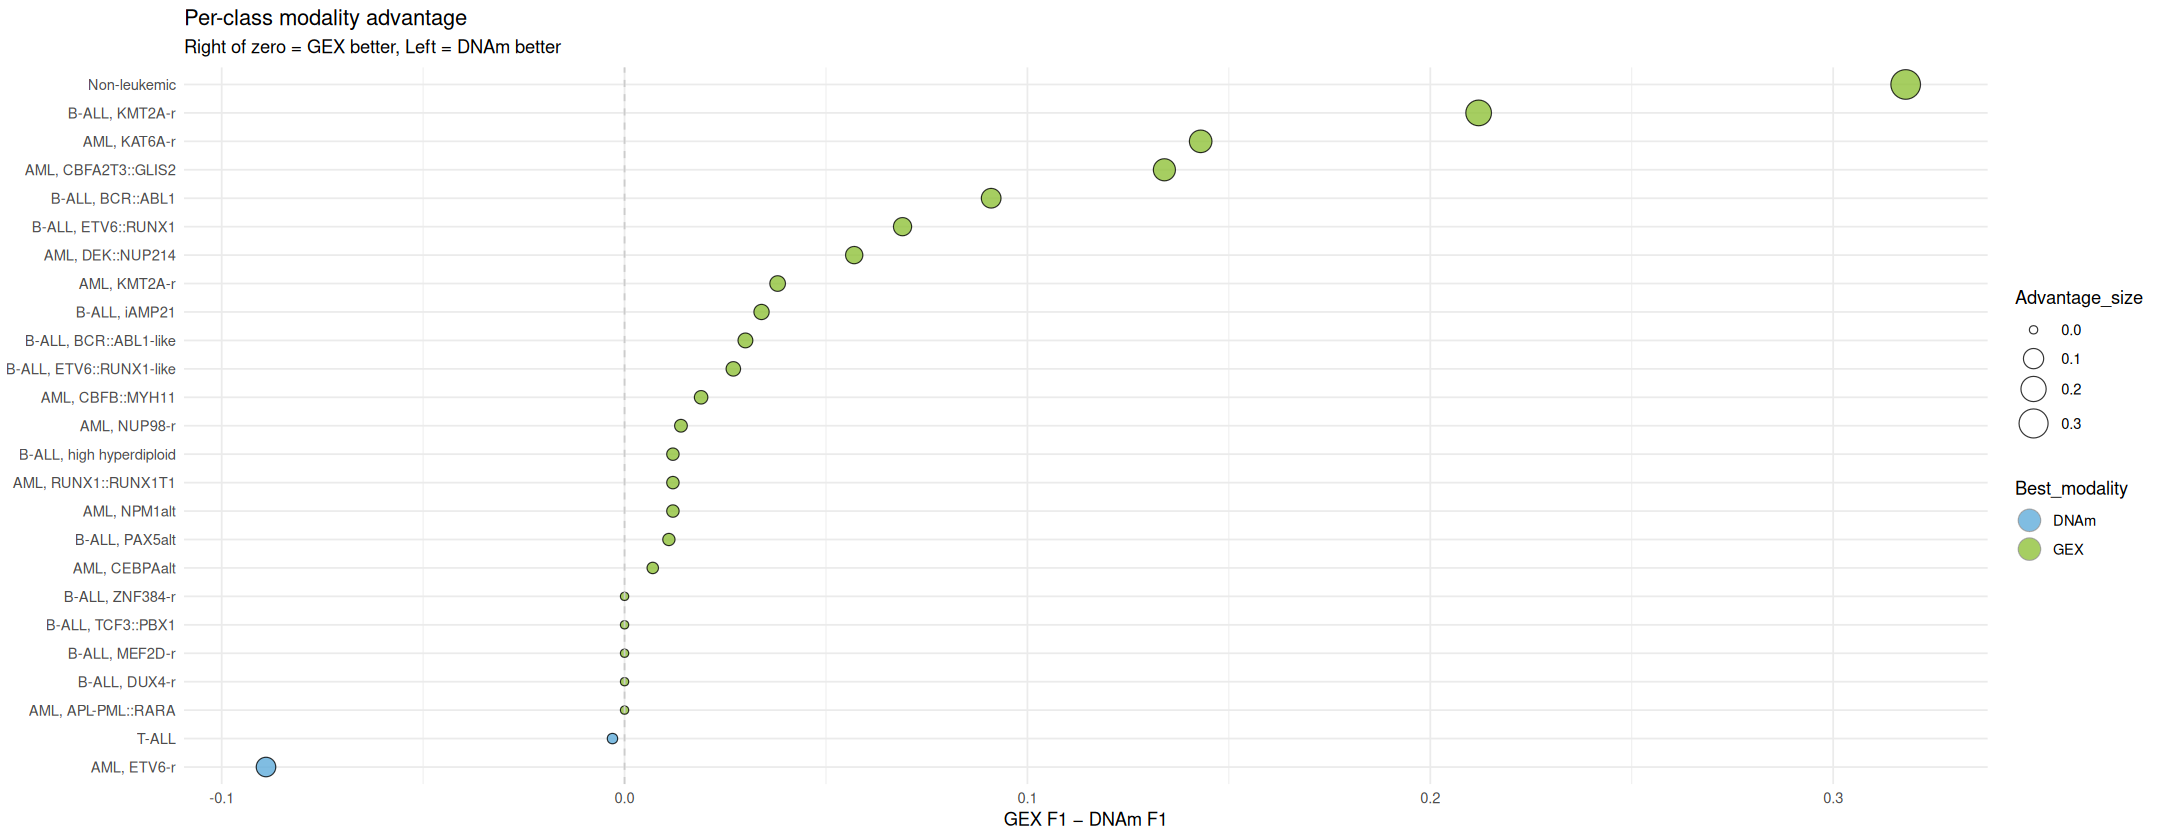

In [ ]:
# Using per_class_f1() from earlier
complement_df <- data.frame(
  Class = classes,
  GEX   = f1_gex$F1,
  DNAm  = f1_dnam$F1
) |>
  mutate(
    GEX_advantage  = GEX - DNAm,
    Best_modality  = ifelse(GEX >= DNAm, "GEX", "DNAm"),
    Advantage_size = abs(GEX - DNAm)
  )

ggplot(complement_df,
       aes(x = GEX_advantage,
           y = reorder(Class, GEX_advantage),
           fill = Best_modality,
           size = Advantage_size)) +
  geom_point(shape = 21, alpha = 0.8) +
  geom_vline(xintercept = 0, linetype = "dashed", colour = "grey80") +
  scale_fill_manual(values = c(GEX = GREEN, DNAm = LIGHTBLUE)) +
  scale_size_continuous(range = c(2, 8)) +
  guides(fill = guide_legend(override.aes = list(colour = "grey60", size = 6))) +
  labs(title    = "Per-class modality advantage",
       subtitle = "Right of zero = GEX better, Left = DNAm better",
       x = "GEX F1 − DNAm F1",
       y = NULL) +
  theme_minimal()

  # Save as svg
ggsave(file.path(REPORT_OUTPUT_DIR, "per_class_modality_advantage_plot_by_advantage_size.svg"),
       width = 8, height = 6, units = "in")


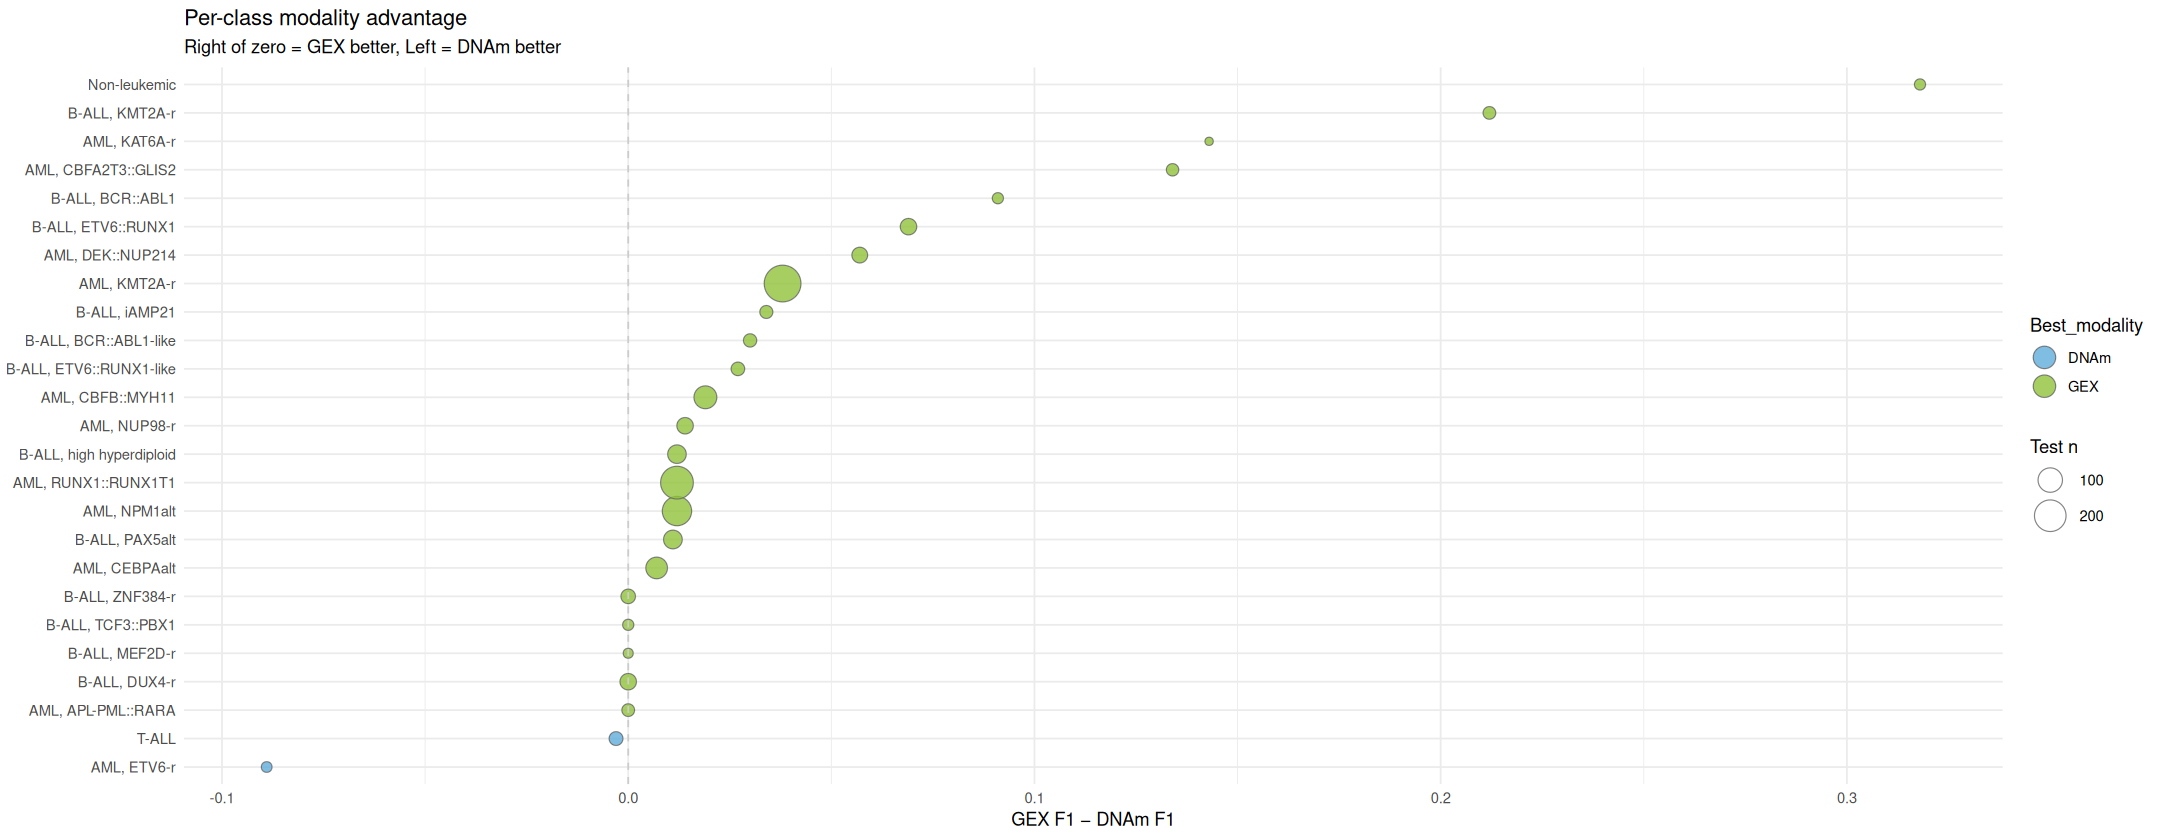

In [ ]:
# Add class sizes
class_n_test <- f1_wide %>% select(Class, n_test)

complement_df <- data.frame(
  Class = classes,
  GEX   = f1_gex$F1,
  DNAm  = f1_dnam$F1
) |>
  mutate(
    GEX_advantage  = GEX - DNAm,
    Best_modality  = ifelse(GEX >= DNAm, "GEX", "DNAm"),
    Advantage_size = abs(GEX - DNAm)
  ) |>
  left_join(class_n_test, by = "Class")

ggplot(complement_df,
       aes(x = GEX_advantage,
           y = reorder(Class, GEX_advantage),
           fill = Best_modality,
           size = n_test)) +
  geom_point(shape = 21, alpha = 0.8, colour = "grey40") +
  guides(fill = guide_legend(override.aes = list(size = 6))) +
  geom_vline(xintercept = 0, linetype = "dashed", colour = "grey80") +
  scale_fill_manual(values = c(GEX = GREEN, DNAm = LIGHTBLUE)) +
  scale_size_continuous(range = c(2, 10), name = "Test n") +
  labs(title    = "Per-class modality advantage",
       subtitle = "Right of zero = GEX better, Left = DNAm better",
       x        = "GEX F1 − DNAm F1",
       y        = NULL) +
  theme_minimal()

  # Save as svg
ggsave(file.path(REPORT_OUTPUT_DIR, "per_class_modality_advantage_plot_by_sample_size.svg"),
       width = 8, height = 6, units = "in")

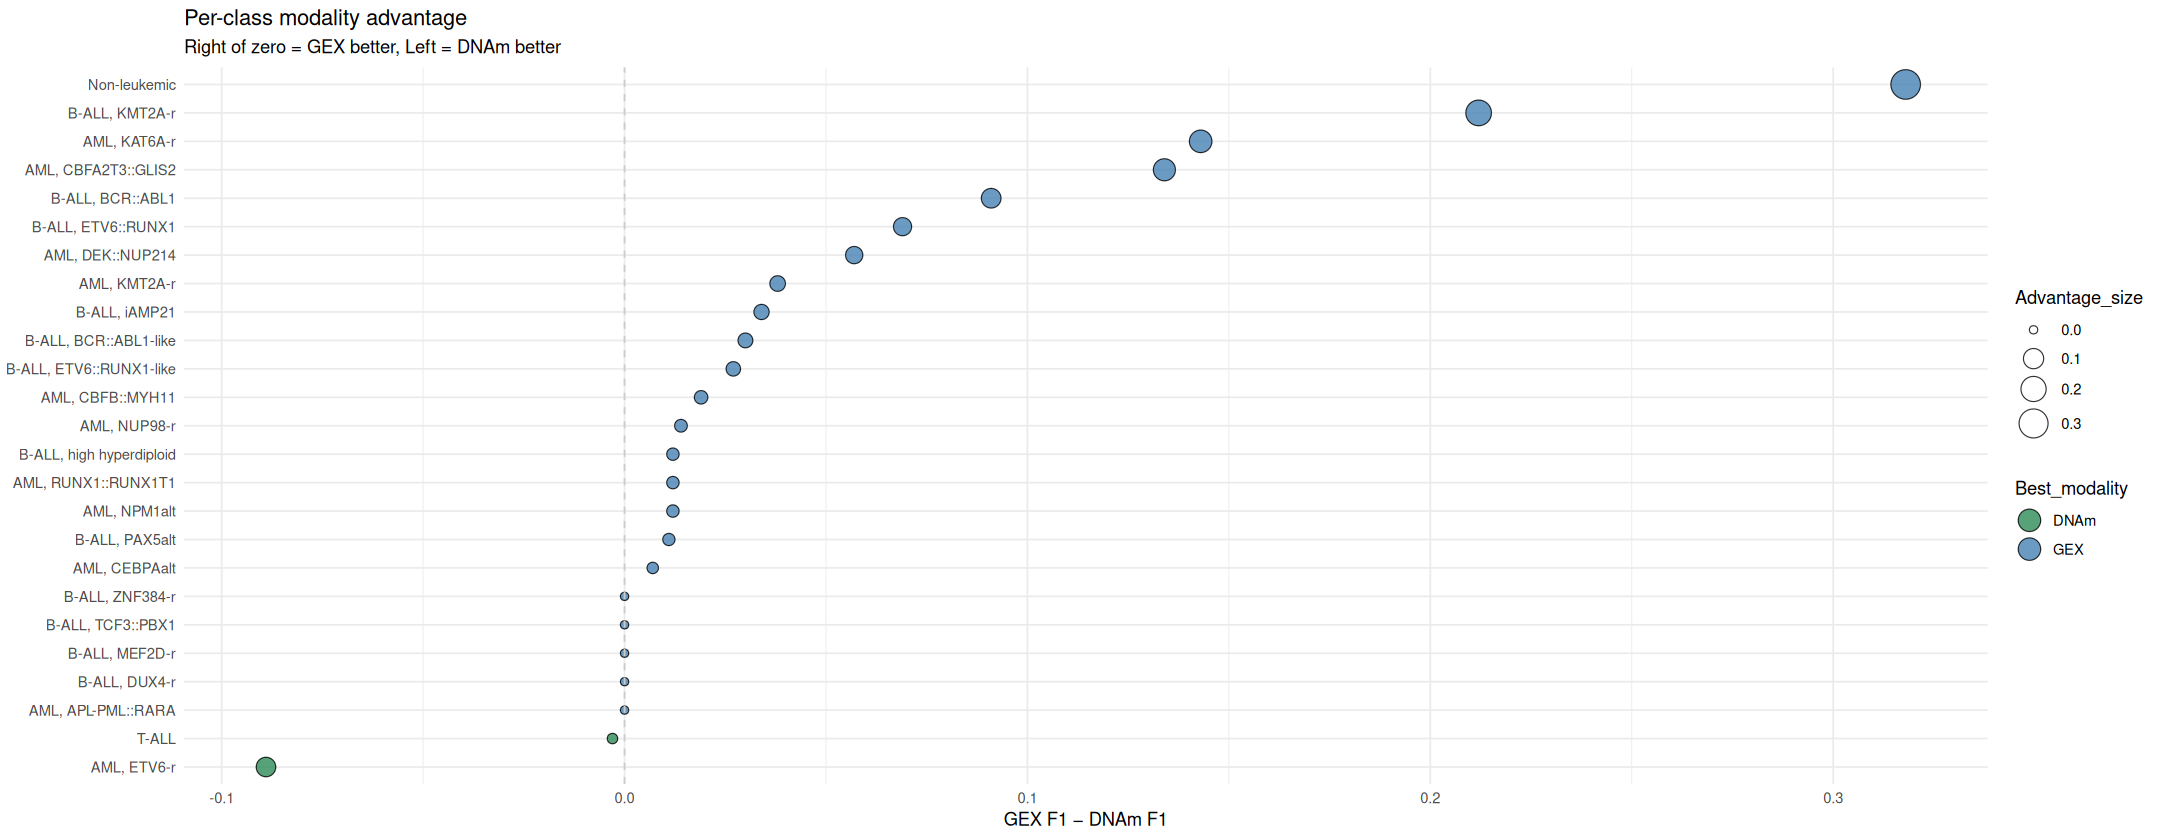

In [ ]:
# Using per_class_f1() from earlier
complement_df <- data.frame(
  Class = classes,
  GEX   = f1_gex$F1,
  DNAm  = f1_dnam$F1
) |>
  mutate(
    GEX_advantage  = GEX - DNAm,
    Best_modality  = ifelse(GEX >= DNAm, "GEX", "DNAm"),
    Advantage_size = abs(GEX - DNAm)
  )

ggplot(complement_df,
       aes(x = GEX_advantage,
           y = reorder(Class, GEX_advantage),
           fill = Best_modality,
           size = Advantage_size)) +
  geom_point(shape = 21, alpha = 0.8) +
  geom_vline(xintercept = 0, linetype = "dashed", colour = "grey80") +
  guides(fill = guide_legend(override.aes = list(size = 6))) +
  scale_fill_manual(values = c(GEX = "steelblue", DNAm = "seagreen")) +
  scale_size_continuous(range = c(2, 8)) +
  labs(title    = "Per-class modality advantage",
       subtitle = "Right of zero = GEX better, Left = DNAm better",
       x = "GEX F1 − DNAm F1",
       y = NULL) +
  theme_minimal()

# Save as svg
ggsave(file.path(REPORT_OUTPUT_DIR, "per_class_modality_advantage_plot.svg"),
       width = 8, height = 6, units = "in")

In [ ]:

# Extract F1 vectors per model
f1_gex_vec    <- f1_wide$GEX
f1_dnam_vec   <- f1_wide$DNAm
f1_diablo_vec <- f1_wide$DIABLO

# ============================================================
# Pairwise Wilcoxon signed-rank tests
# ============================================================
wt_gex_dnam   <- wilcox.test(f1_gex_vec, f1_dnam_vec,
                              paired = TRUE, exact = FALSE)
wt_gex_diablo <- wilcox.test(f1_gex_vec, f1_diablo_vec,
                              paired = TRUE, exact = FALSE)
wt_dnam_diablo <- wilcox.test(f1_dnam_vec, f1_diablo_vec,
                               paired = TRUE, exact = FALSE)

# ============================================================
# Summary table
# ============================================================
wilcox_results <- data.frame(
  Comparison     = c("GEX vs DNAm", "GEX vs DIABLO", "DNAm vs DIABLO"),
  Mean_F1_A      = round(c(mean(f1_gex_vec),
                            mean(f1_gex_vec),
                            mean(f1_dnam_vec)), 3),
  Mean_F1_B      = round(c(mean(f1_dnam_vec),
                            mean(f1_diablo_vec),
                            mean(f1_diablo_vec)), 3),
  W_statistic    = c(wt_gex_dnam$statistic,
                     wt_gex_diablo$statistic,
                     wt_dnam_diablo$statistic),
  p_value        = round(c(wt_gex_dnam$p.value,
                            wt_gex_diablo$p.value,
                            wt_dnam_diablo$p.value), 4),
  p_adj_BH       = round(p.adjust(c(wt_gex_dnam$p.value,
                                     wt_gex_diablo$p.value,
                                     wt_dnam_diablo$p.value),
                                   method = "BH"), 4)
)

print(wilcox_results)

      Comparison Mean_F1_A Mean_F1_B W_statistic p_value p_adj_BH
1    GEX vs DNAm     0.959     0.913         194  0.0009   0.0028
2  GEX vs DIABLO     0.959     0.953          29  0.1415   0.1415
3 DNAm vs DIABLO     0.913     0.953          23  0.0040   0.0060
